In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Regression

Random-forest performance is evaluated with five-fold cross-validation repeated ten times. The same reproducible splits are used for every landscape representation, and metrics are reported as the mean $\pm$ standard deviation across the 50 test folds.

Zero-tendril samples: 53/1000


,feature_label,target,mode_filter,n_samples,n_features,n_test_folds,mae_mean,mae_sd,rmse_mean,rmse_sd,r2_mean,r2_sd
0,avg_tendril_length,n_tendrils,single_uniform,1000,260,50,3.856589,0.193067,4.905184,0.221850,0.344747,0.061119
1,signed_circularity_complement,n_tendrils,single_uniform,1000,260,50,0.636337,0.038190,0.899426,0.070306,0.977871,0.003610
2,signed_excess_curvature,n_tendrils,single_uniform,1000,260,50,0.319941,0.019652,0.465741,0.025506,0.994079,0.000737
3,standard_landscapes,n_tendrils,single_uniform,1000,260,50,2.375631,0.137836,3.249675,0.196512,0.711731,0.037489
4,tendril_count,n_tendrils,single_uniform,1000,260,50,0.160616,0.019635,0.326685,0.045963,0.997041,0.000861
5,unsigned_circularity_complement,n_tendrils,single_uniform,1000,260,50,0.612460,0.033801,0.835113,0.045864,0.980949,0.002552
6,unsigned_excess_curvature,n_tendrils,single_uniform,1000,260,50,0.575283,0.031757,0.742338,0.041472,0.984950,0.001923
7,avg_tendril_length,tendril_length,single_uniform,1000,260,50,0.002357,0.000168,0.003643,0.000540,0.997961,0.000691
8,signed_circularity_complement,tendril_length,single_uniform,1000,260,50,0.012376,0.000939,0.019171,0.001877,0.944501,0.011371
9,signed_excess_curvature,tendril_length,single_uniform,1000,260,50,0.015181,0.001092,0.021505,0.001458,0.930584,0.009387


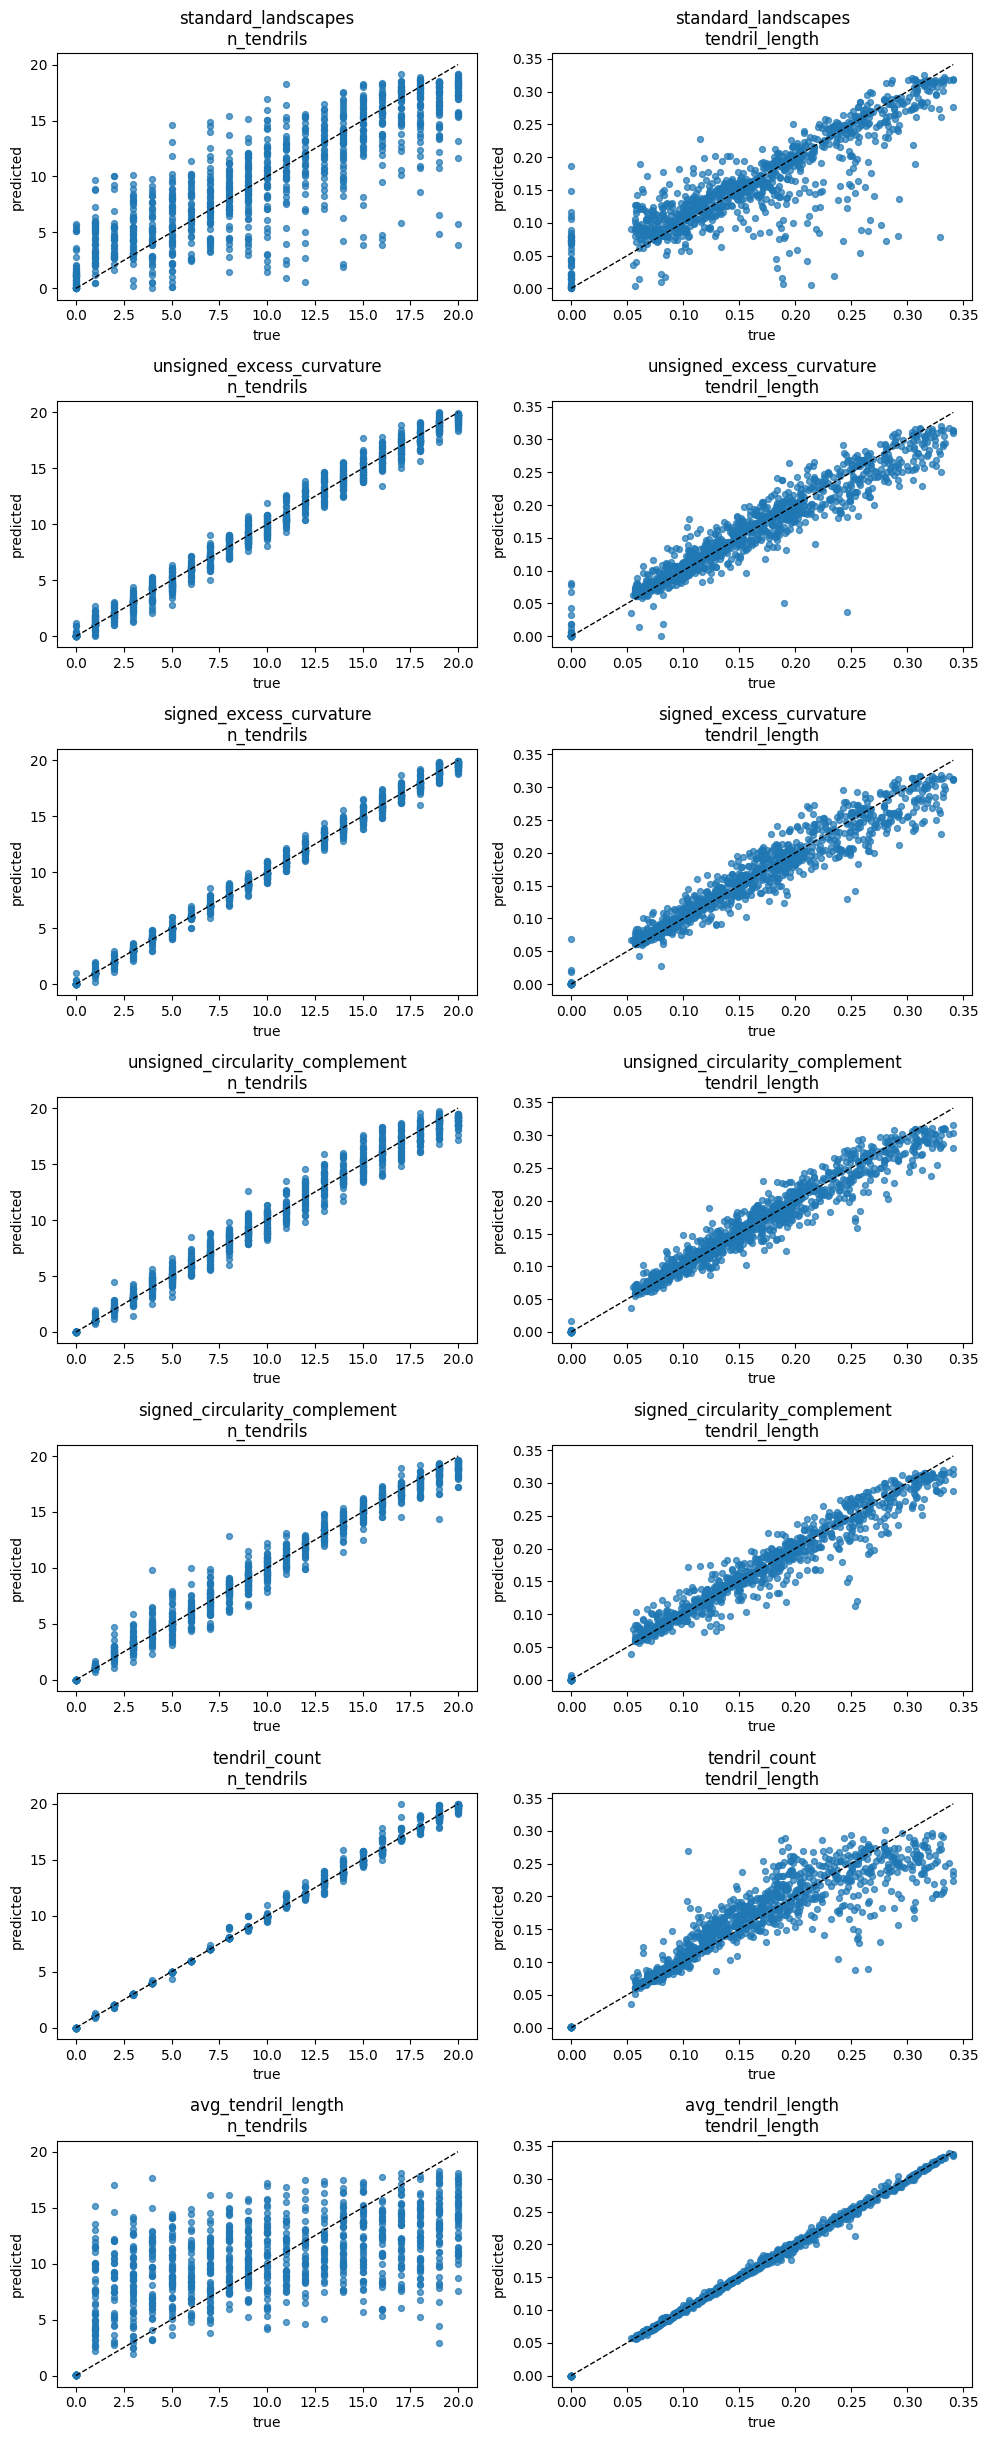

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RepeatedKFold


feature_dir = Path("outputs/features_single_uniform")
labels = [
    "standard_landscapes",
    "unsigned_excess_curvature",
    "signed_excess_curvature",
    "unsigned_circularity_complement",
    "signed_circularity_complement",
    "tendril_count",
    "avg_tendril_length",
]
targets = ["n_tendrils", "tendril_length"]
mode_filters = {
    "all": {},
    "non_polarized": {"root_mode": ["uniform"]},
    "polarized": {"root_mode": ["polarized"]},
    "single": {"tendril_mode": ["single"]},
    "branching": {"tendril_mode": ["branching"]},
    "single_uniform": {"tendril_mode": ["single"], "root_mode": ["uniform"]},
}
active_mode_filter = "single_uniform"
n_splits = 5
n_repeats = 10
cv_random_state = 0
rf_random_state = 0

if active_mode_filter not in mode_filters:
    raise ValueError(f"Unknown mode filter {active_mode_filter!r}. Available filters: {list(mode_filters)}")


missing_feature_paths = [feature_dir / f"{label}.csv" for label in labels if not (feature_dir / f"{label}.csv").exists()]
if missing_feature_paths:
    missing_paths = "\n".join(str(path) for path in missing_feature_paths)
    raise FileNotFoundError(
        "Missing feature CSVs. Generate them with featurize_point_clouds.py.\n"
        f"Missing paths:\n{missing_paths}"
    )

feature_frames = {}
feature_columns_by_label = {}
for label in labels:
    df = pd.read_csv(feature_dir / f"{label}.csv")
    for mode_column, allowed_values in mode_filters[active_mode_filter].items():
        if mode_column not in df.columns:
            raise ValueError(f"Column {mode_column!r} not found in {feature_dir / f'{label}.csv'}")
        df = df[df[mode_column].isin(allowed_values)].copy()
    if len(df) < n_splits:
        raise ValueError(
            f"Mode filter {active_mode_filter!r} leaves only {len(df)} rows in {feature_dir / f'{label}.csv'}"
        )
    if df["sample_id"].duplicated().any():
        raise ValueError(f"Duplicate sample IDs in {feature_dir / f'{label}.csv'}")
    df = df.sort_values("sample_id").reset_index(drop=True)

    feature_columns = [column for column in df.columns if column.startswith("f") and column[1:].isdigit()]
    if not feature_columns:
        raise ValueError(f"No feature columns found in {feature_dir / f'{label}.csv'}")

    feature_frames[label] = df
    feature_columns_by_label[label] = feature_columns

reference_df = feature_frames[labels[0]]
reference_ids = reference_df["sample_id"].to_numpy()
for label, df in feature_frames.items():
    if not np.array_equal(df["sample_id"].to_numpy(), reference_ids):
        raise ValueError(f"Sample IDs for {label!r} do not match the reference feature file")
    for target in targets:
        if not np.allclose(df[target].to_numpy(), reference_df[target].to_numpy()):
            raise ValueError(f"Target {target!r} for {label!r} does not match the reference feature file")

cv = RepeatedKFold(
    n_splits=n_splits,
    n_repeats=n_repeats,
    random_state=cv_random_state,
)
cv_splits = list(cv.split(reference_ids))

rf_fold_metrics = []
rf_predictions = {}

for label in labels:
    df = feature_frames[label]
    feature_columns = feature_columns_by_label[label]
    X = df[feature_columns].to_numpy()

    for target in targets:
        y = df[target].to_numpy()
        first_repeat_predictions = np.full(len(y), np.nan)

        for split_index, (train_indices, test_indices) in enumerate(cv_splits):

            rf_regressor = RandomForestRegressor(
                n_estimators=500,
                min_samples_leaf=2,
                random_state=rf_random_state,
                n_jobs=-1,
            )
            rf_regressor.fit(X[train_indices], y[train_indices])
            y_pred = rf_regressor.predict(X[test_indices])
            y_test = y[test_indices]

            if split_index < n_splits:
                first_repeat_predictions[test_indices] = y_pred

            rf_fold_metrics.append(
                {
                    "feature_label": label,
                    "target": target,
                    "mode_filter": active_mode_filter,
                    "split_index": split_index,
                    "repeat": split_index // n_splits,
                    "fold": split_index % n_splits,
                    "n_samples": len(df),
                    "n_features": len(feature_columns),
                    "n_train": len(train_indices),
                    "n_test": len(test_indices),
                    "mae": mean_absolute_error(y_test, y_pred),
                    "rmse": mean_squared_error(y_test, y_pred) ** 0.5,
                    "r2": r2_score(y_test, y_pred),
                }
            )

        if np.isnan(first_repeat_predictions).any():
            raise RuntimeError("The first CV repeat did not predict every sample exactly once")
        rf_predictions[(label, target)] = (y, first_repeat_predictions)

rf_fold_metrics = pd.DataFrame(rf_fold_metrics)
rf_regression_metrics = (
    rf_fold_metrics.groupby(["feature_label", "target", "mode_filter"], as_index=False)
    .agg(
        n_samples=("n_samples", "first"),
        n_features=("n_features", "first"),
        n_test_folds=("split_index", "count"),
        mae_mean=("mae", "mean"),
        mae_sd=("mae", "std"),
        rmse_mean=("rmse", "mean"),
        rmse_sd=("rmse", "std"),
        r2_mean=("r2", "mean"),
        r2_sd=("r2", "std"),
    )
    .sort_values(["target", "feature_label"])
    .reset_index(drop=True)
)
n_zero_tendril_samples = int((reference_df["n_tendrils"] == 0).sum())
print(f"Zero-tendril samples: {n_zero_tendril_samples}/{len(reference_df)}")
display(rf_regression_metrics)

fig, axes = plt.subplots(
    len(labels),
    len(targets),
    figsize=(5 * len(targets), 3.5 * len(labels)),
    squeeze=False,
)

for row_index, label in enumerate(labels):
    for col_index, target in enumerate(targets):
        ax = axes[row_index, col_index]
        y_test, y_pred = rf_predictions[(label, target)]
        ax.scatter(y_test, y_pred, s=18, alpha=0.7)

        min_value = min(y_test.min(), y_pred.min())
        max_value = max(y_test.max(), y_pred.max())
        ax.plot([min_value, max_value], [min_value, max_value], color="black", linestyle="--", linewidth=1)

        ax.set_title(f"{label}\n{target}")
        ax.set_xlabel("true")
        ax.set_ylabel("predicted")

fig.tight_layout()
plt.show()

# Regression without branching and polarization - Publication plot

In [3]:
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.size": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "figure.dpi": 300,
    "axes.grid": False,
    "grid.color": "#d3d3d3",
    "grid.linewidth": 0.5,
    "axes.linewidth": 0.8,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
})

latex_textwidth = 448.13095
latex_linewidth = 448.13095

inches_per_pt = 1/72.27
width = latex_linewidth * inches_per_pt

print(width)

linewidth_fraction = 1

publication_labels = [
    "standard_landscapes",
    "unsigned_excess_curvature",
    "signed_excess_curvature",
    "tendril_count",
    "avg_tendril_length"]

#figsize used to be figsize=(7.2, 2.05 * n_rows + 0.8)
n_rows = len(labels)
height_width_ratio = (1.7 * n_rows + 0.9) / 7.2

6.20078801715788


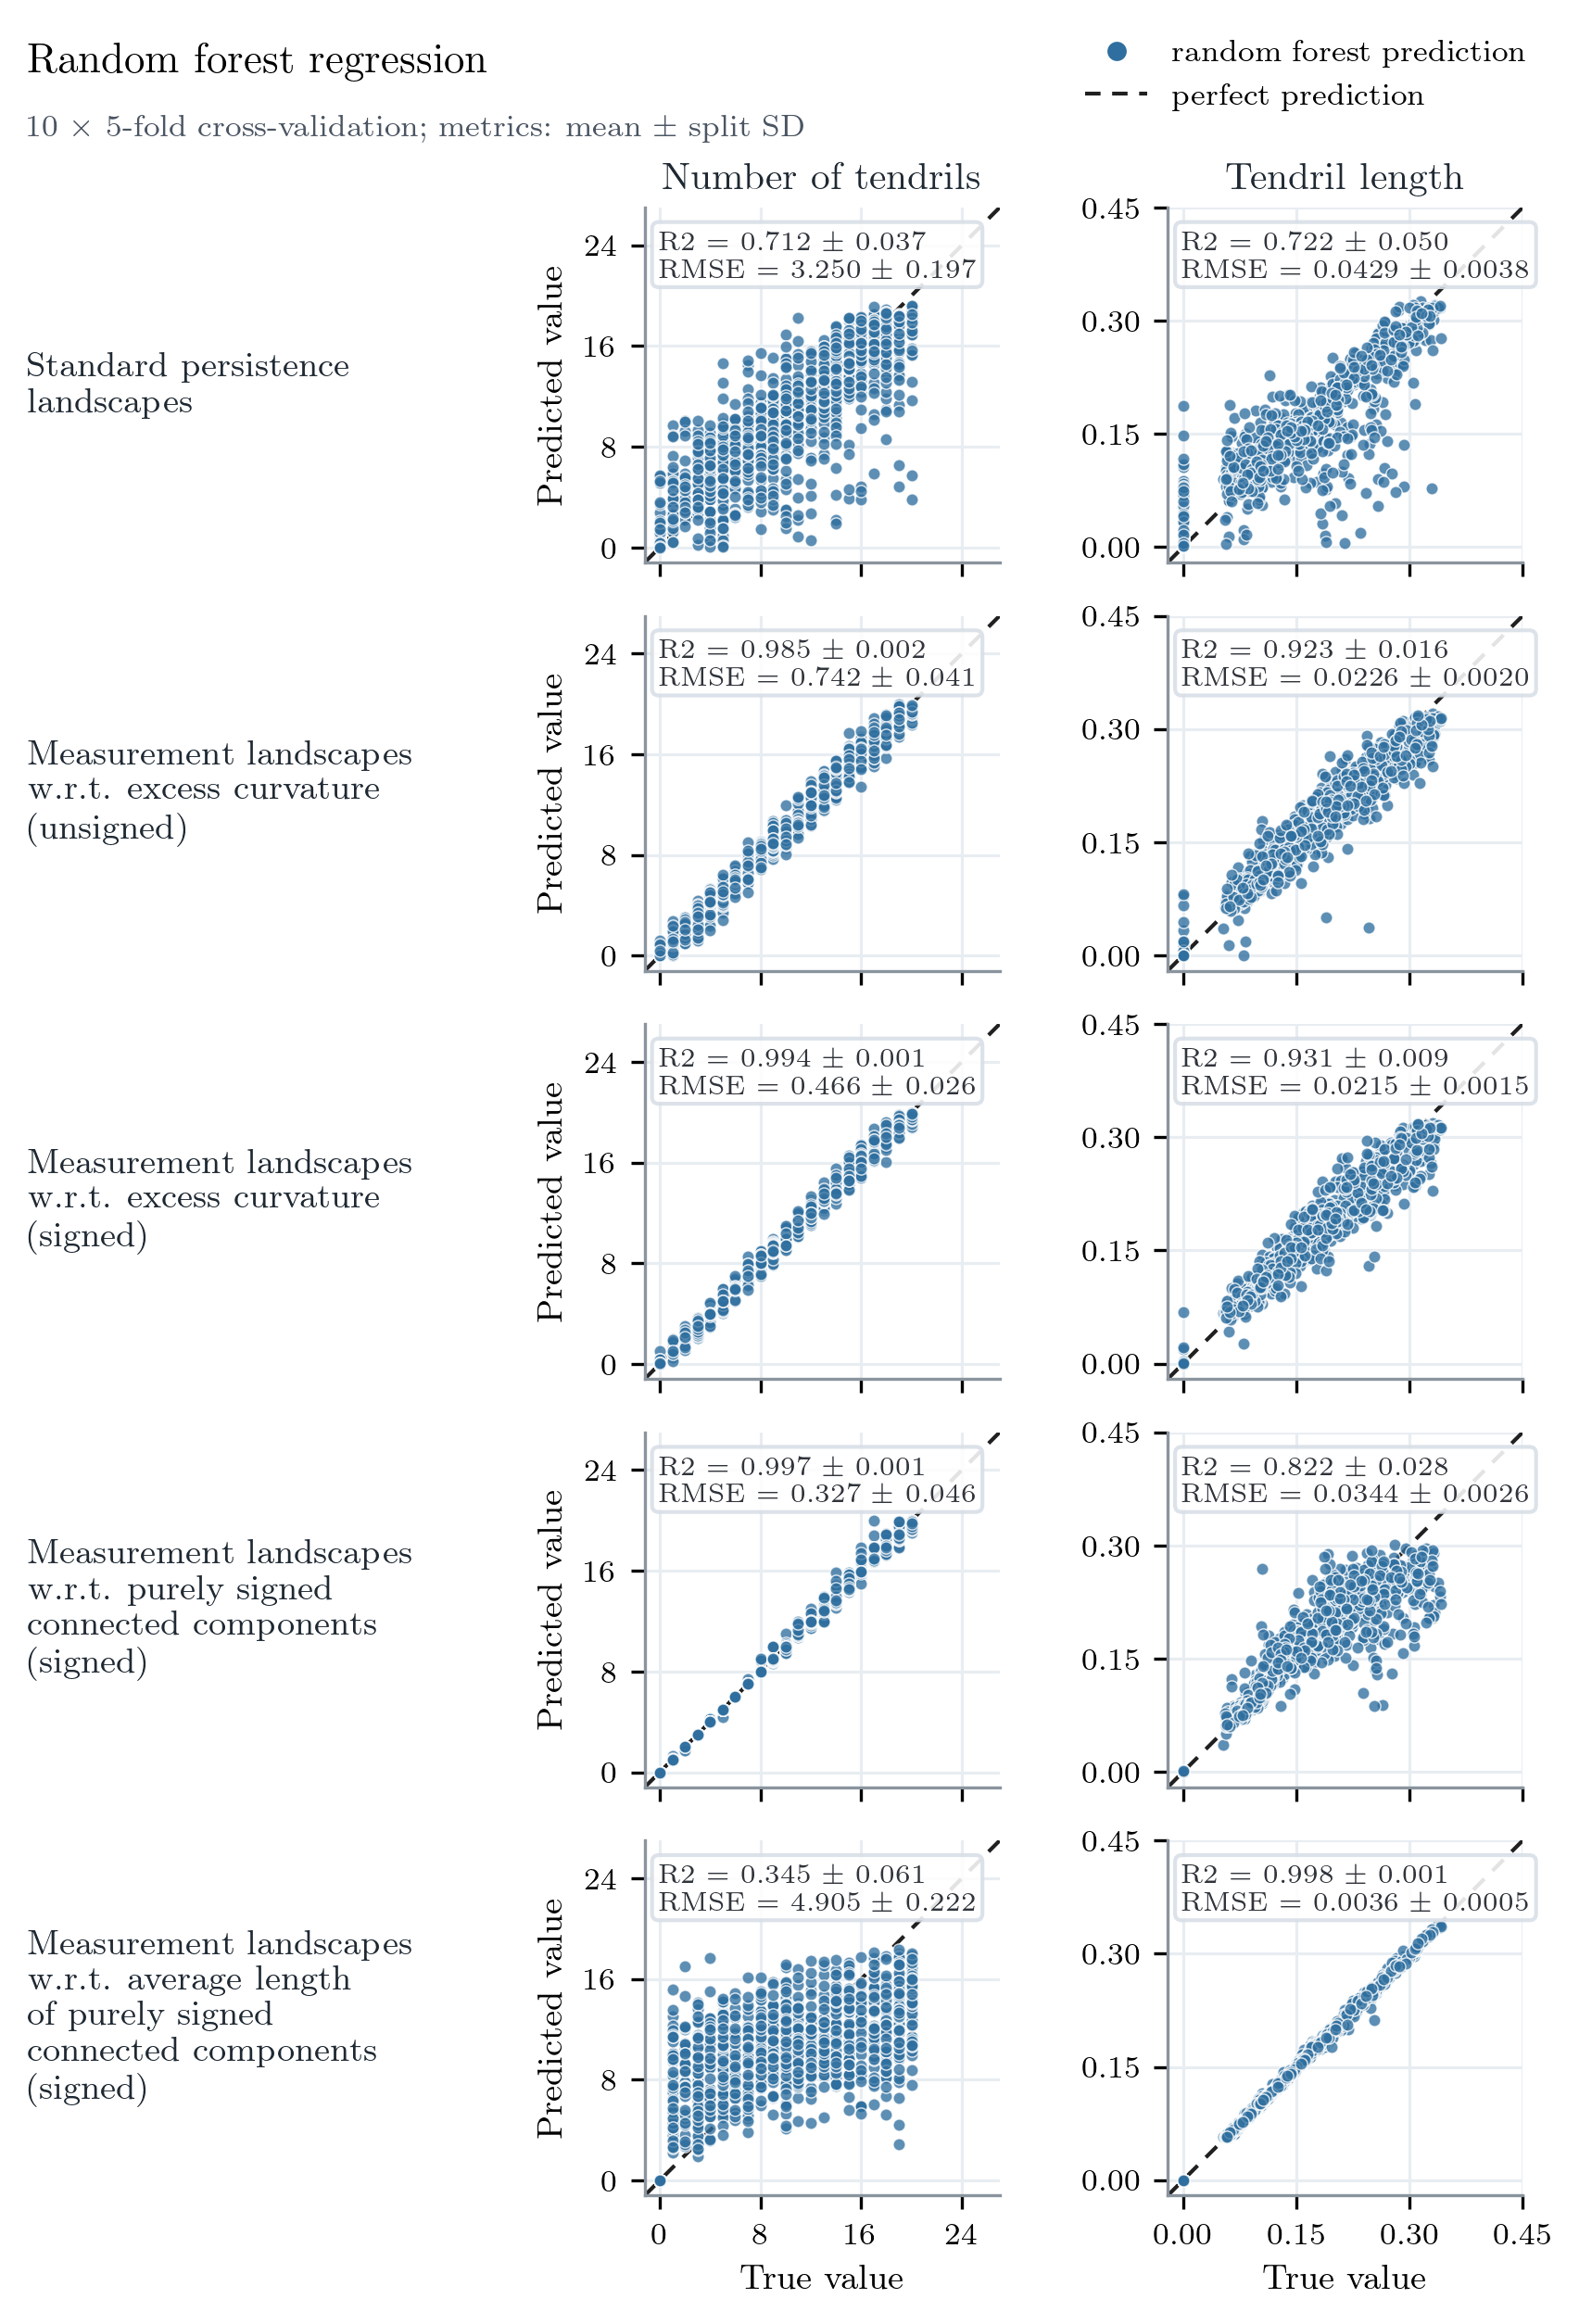

In [12]:
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator


publication_labels = [
    "standard_landscapes",
    "unsigned_excess_curvature",
    "signed_excess_curvature",
    "tendril_count",
    "avg_tendril_length"]
publication_targets = targets
column_xy_max = {
    "n_tendrils": 27.0,
    "tendril_length": 0.45,
}

feature_titles = {
    "standard_landscapes": "Standard persistence\nlandscapes",
    "unsigned_excess_curvature": "Measurement landscapes\nw.r.t. excess curvature\n(unsigned)",
    "signed_excess_curvature": "Measurement landscapes\nw.r.t. excess curvature\n(signed)",
    "unsigned_circularity_complement": "Measurement landscapes\nw.r.t. non-circularity\n(unsigned)",
    "signed_circularity_complement": "Measurement landscapes\nw.r.t. non-circularity\n(signed)",
    "tendril_count": "Measurement landscapes\nw.r.t. purely signed \nconnected components\n(signed)",
    "avg_tendril_length": "Measurement landscapes\nw.r.t. average length \nof purely signed\nconnected components\n(signed)",
}
target_titles = {
    "n_tendrils": "Number of tendrils",
    "tendril_length": "Tendril length",
}

missing_predictions = [
    (feature_label, target)
    for feature_label in publication_labels
    for target in publication_targets
    if (feature_label, target) not in rf_predictions
]
if missing_predictions:
    raise KeyError(f"Missing random forest predictions for: {missing_predictions}")

metric_lookup = rf_regression_metrics.set_index(["feature_label", "target"])



n_rows = len(publication_labels)
n_cols = len(publication_targets)
fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(width, 0.75*width*height_width_ratio),
    sharex="col",
    sharey="col",
    squeeze=False,
)
fig.subplots_adjust(left=0.4, right=0.965, bottom=0.05, top=0.915, wspace=0.16, hspace=0.15)

column_limits = {}
for target in publication_targets:
    values = []
    for feature_label in publication_labels:
        y_true, y_pred = rf_predictions[(feature_label, target)]
        values.extend([np.asarray(y_true), np.asarray(y_pred)])
    values = np.concatenate(values)
    low = float(np.nanmin(values))
    data_high = float(np.nanmax(values))
    padding = 0.06 * (data_high - low) if data_high > low else 1.0
    configured_high = float(column_xy_max[target])
    if configured_high < data_high:
        raise ValueError(
            f"Configured axis maximum {configured_high} for {target!r} would clip data up to {data_high}"
        )
    column_limits[target] = (low - padding, configured_high)

point_color = "#2f6f9f"
identity_color = "#202020"
grid_color = "#e8edf2"

for row_index, feature_label in enumerate(publication_labels):
    for col_index, target in enumerate(publication_targets):
        ax = axes[row_index, col_index]
        y_true, y_pred = rf_predictions[(feature_label, target)]
        y_true = np.asarray(y_true)
        y_pred = np.asarray(y_pred)
        low, high = column_limits[target]

        ax.scatter(
            y_true,
            y_pred,
            s=10,
            color=point_color,
            edgecolor="white",
            linewidth=0.35,
            alpha=0.78,
            zorder=3,
        )
        ax.plot([low, high], [low, high], color=identity_color, linestyle=(0, (4, 3)), linewidth=1.0, zorder=2)
        ax.set_xlim(low, high)
        ax.set_ylim(low, high)
        ax.set_box_aspect(1)
        ax.grid(True, color=grid_color, linewidth=0.75)
        ax.set_axisbelow(True)
        ax.xaxis.set_major_locator(MaxNLocator(nbins=4, prune=None))
        ax.yaxis.set_major_locator(MaxNLocator(nbins=4, prune=None))

        for spine in ["top", "right"]:
            ax.spines[spine].set_visible(False)
        for spine in ["left", "bottom"]:
            ax.spines[spine].set_color("#8a949e")
            ax.spines[spine].set_linewidth(0.8)

        metric_row = metric_lookup.loc[(feature_label, target)]
        rmse_decimals = 3 if target == "n_tendrils" else 4
        ax.text(
            0.04,
            0.94,
            (
                f"R2 = {metric_row['r2_mean']:.3f} $\\pm$ {metric_row['r2_sd']:.3f}\n"
                f"RMSE = {metric_row['rmse_mean']:.{rmse_decimals}f} $\\pm$ "
                f"{metric_row['rmse_sd']:.{rmse_decimals}f}"
            ),
            transform=ax.transAxes,
            ha="left",
            va="top",
            fontsize=7,
            color="#30343b",
            bbox={"boxstyle": "round,pad=0.25", "facecolor": "white", "edgecolor": "#d8dee6", "alpha": 0.88},
        )

        if row_index == n_rows - 1:
            ax.set_xlabel("True value")
        else:
            ax.tick_params(labelbottom=False)
        if col_index == 0:
            ax.set_ylabel("Predicted value")
        #else:
            #ax.tick_params(labelleft=False)

fig.canvas.draw()

for col_index, target in enumerate(publication_targets):
    position = axes[0, col_index].get_position()
    fig.text(
        (position.x0 + position.x1) / 2,
        0.92,
        target_titles.get(target, target.replace("_", " ").title()),
        ha="center",
        va="bottom",
        #fontweight="bold",
        color="#1f2933",
        fontsize = 10,
    )

for row_index, feature_label in enumerate(publication_labels):
    position = axes[row_index, 0].get_position()
    fig.text(
        0.07,
        (position.y0 + position.y1) / 2,
        feature_titles.get(feature_label, feature_label.replace("_", " ").title()),
        ha="left",
        va="center",
        #fontweight="bold",
        color="#1f2933",
    )

fig.suptitle(
    "Random forest regression",
    x=0.07,
    y=0.986,
    ha="left",
    fontweight="bold",
)
fig.text(
    0.07,
    0.955,
    "10 $\\times$ 5-fold cross-validation; metrics: mean $\\pm$ split SD",
    ha="left",
    va="top",
    fontsize=8,
    color="#4b5563",
)
fig.legend(
    handles=[
        Line2D([0], [0], marker="o", color="none", markerfacecolor=point_color, markeredgecolor="white", markersize=6, label="random forest prediction"),
        Line2D([0], [0], color=identity_color, linestyle=(0, (4, 3)), linewidth=1.0, label="perfect prediction"),
    ],
    loc="upper right",
    bbox_to_anchor=(0.955, 1),
    frameon=False,
    #fontsize=8.5,
)

plt.savefig("outputs/tendril_regression.pdf", dpi=300)
plt.savefig("outputs/single_uniform_regression_plot.png", dpi=300)
plt.show()

# Plot example graphs and point clouds

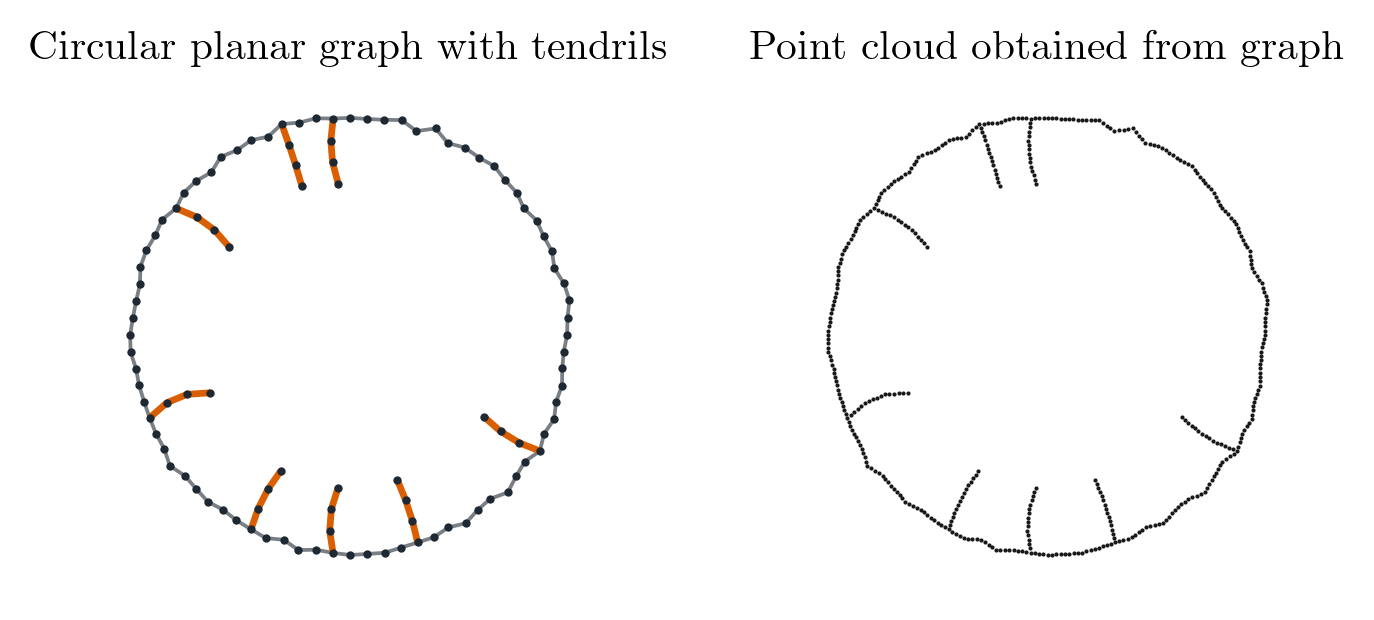

In [5]:
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from loop_tendrils import generate_parametric_loop_tendrils
from persforest import PersistenceForest
from plotting import plot_planar_graph
from sampling import sample_planar_graph

def plot_loop_tendril_generation_example(
    n_tendrils,
    tendril_length,
    *,
    root_mode="uniform",
    tendril_mode="single",
    branching_probability=0.0,
    seed=7,
    n_loop_vertices=80,
    loop_noise=0.01,
    target_spacing=0.015,
    scale_death_to=1.0,
    save_path=None,
):
    graph = generate_parametric_loop_tendrils(
        n_tendrils=int(n_tendrils),
        tendril_length=float(tendril_length),
        tendril_mode=tendril_mode,
        root_mode=root_mode,
        branching_probability=float(branching_probability),
        n_loop_vertices=int(n_loop_vertices),
        loop_noise=float(loop_noise),
        normalize=False,
        seed=seed,
    )

    scale_cloud = sample_planar_graph(
        graph=graph,
        target_spacing=0.15,
        pre_sample_noise_std=0.01,
        post_sample_noise_std=0.0008,
        seed=seed,
    )
    death = PersistenceForest(scale_cloud).max_bar().death
    scaling = float(scale_death_to) / death

    point_cloud = sample_planar_graph(
        graph=graph,
        target_spacing=float(target_spacing) / scaling,
        pre_sample_noise_std=0.0,
        post_sample_noise_std=0.0,
        seed=seed,
        return_metadata=False,
    ) * scaling # type: ignore
    scaled_graph = replace(graph, nodes=np.asarray(graph.nodes) * scaling)

    fig, axes = plt.subplots(1, 2, figsize=(width*0.75, width*0.9*0.35), constrained_layout=True)

    plot_planar_graph(
        scaled_graph,
        ax=axes[0],
        node_size=4,
        edge_width=0.9,
        edge_color="#7a7f86",
        node_color="#1f2933",
        show_nodes=True,
        highlight_metadata=True,
    )
    axes[0].set_title("Circular planar graph with tendrils",  fontsize =10)

    axes[1].scatter(
        point_cloud[:, 0],
        point_cloud[:, 1],
        s=1,
        color="black",
        linewidths=0,
        alpha=0.9,
    )
    axes[1].set_title("Point cloud obtained from graph", fontsize =10)
    axes[1].set_aspect("equal", adjustable="box")
    axes[1].margins(0.08)
    axes[1].set_xticks([])
    axes[1].set_yticks([])
    for spine in axes[1].spines.values():
        spine.set_visible(False)

    if save_path is not None:
        save_path = Path(save_path)
        save_path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=300, bbox_inches="tight")

    return fig, axes, graph, point_cloud

n_tendrils = 8
tendril_length = 0.3

fig, axes, graph, point_cloud = plot_loop_tendril_generation_example(
    n_tendrils=n_tendrils,
    tendril_length=tendril_length,
    root_mode="uniform",
    tendril_mode="single",
    seed=4,
    save_path=f"outputs/loop_tendril_generation_example_n-tendrils{n_tendrils}.pdf",
)

plt.show()